# Treasure Hunt Game Notebook

## Read and Review Your Starter Code
The theme of this project is a popular treasure hunt game in which the player needs to find the treasure before the pirate does. While you will not be developing the entire game, you will write the part of the game that represents the intelligent agent, which is a pirate in this case. The pirate will try to find the optimal path to the treasure using deep Q-learning. 

<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>TreasureHuntGame_starterCode.ipynb</b> file to complete your assignment. 
<br><br>
You have been provided with two Python classes and this notebook to help you with this assignment. The first class, <b>TreasureMaze.py</b>, represents the environment, which includes a maze object defined as a matrix. The second class, <b>GameExperience.py</b>, stores the episodes – that is, all the states that come in between the initial state and the terminal state. This is later used by the agent for learning by experience, called "exploration". This notebook shows how to play a game. Your task is to complete the deep Q-learning implementation in the qtrain() function for which a skeleton implementation has been provided. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
<b>NOTE: </b>The code block you will need to complete will have <b>#TODO</b> as a header.
<br> First, read and review the next few code and instruction blocks to understand the code that you have been given.</div>

<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [22]:
import sys
import numpy as np

print("Python:", sys.executable)
print("NumPy:", np.__version__)

Python: /usr/local/bin/python3
NumPy: 1.26.4


In [ ]:

%pip install -r requirements.txt

<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

In [ ]:
from __future__ import print_function
import os, sys, time, datetime, json, random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, Activation, PReLU
from keras.optimizers import SGD , Adam, RMSprop
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience
%matplotlib inline

<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [ ]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [ ]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The <b>pirate agent</b> can move in four directions: left, right, up, and down. 

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note:</b> While the agent primarily learns by experience through exploitation, often, the agent can choose to explore the environment to find previously undiscovered paths. This is called "exploration" and is defined by epsilon. This value is the <b>EXPLORATION</b> values from the Cartpole assignment. The hyperparameters are provided here and used in the <b>qtrain()</b> method. 
You are encouraged to try various values for the exploration factor and see how the algorithm performs.
</div>

In [ ]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04


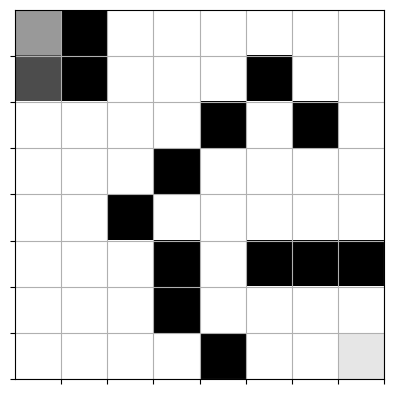

In [ ]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [12]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()
    steps = 0
    if max_steps is None:
        max_steps = qmaze.maze.size * 4  # safety cutoff

    while steps < max_steps:
        state = np.asarray(envstate, dtype=np.float32)
        if state.ndim == 1:
            state = np.expand_dims(state, axis=0)

        q_values = model(state, training=False).numpy()
        action = np.argmax(q_values[0])

        envstate, reward, game_status = qmaze.act(action)
        steps += 1

        if game_status == 'win':
            return True
        elif game_status == 'lose':
            return False

    return False  # timed out with no result

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
    This <b>completion_check()</b> function helps you to determine whether the pirate can win any game at all. If your maze is not well designed, the pirate may not win any game at all. In this case, your training would not yield any result. The provided maze in this notebook ensures that there is a path to win and you can run this method to check.
</div>

In [13]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [7]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

In [23]:

# CS 499: Check actual DQN training dependencies.

required = [
    "np",
    "random",
    "datetime",
    "Sequential",
    "Dense",
    "PReLU",
    "clone_model",
    "num_actions",
    "epsilon_decay",
    "epsilon_min",
    "train_step",
    "format_time",
    "TreasureMaze",
    "GameExperience",
    "StatusExperience",
    "build_model",
    "qtrain",
    "play_game",
    "completion_check",
    "maze"
]

missing = []

for name in required:
    if name in globals():
        print(name, "READY")
    else:
        print(name, "MISSING")
        missing.append(name)

if not missing:
    print("\nAll checked DQN dependencies are ready!")
else:
    print("\nStill missing:", missing)



np READY
random MISSING
datetime MISSING
Sequential MISSING
Dense MISSING
PReLU MISSING
clone_model MISSING
num_actions MISSING
epsilon_decay MISSING
epsilon_min MISSING
train_step MISSING
format_time READY
TreasureMaze READY
GameExperience READY
StatusExperience READY
build_model READY
qtrain READY
play_game READY
completion_check READY
maze MISSING

Still missing: ['random', 'datetime', 'Sequential', 'Dense', 'PReLU', 'clone_model', 'num_actions', 'epsilon_decay', 'epsilon_min', 'train_step', 'maze']


In [26]:

required = [
    "random", "datetime", "Sequential",
    "Dense", "PReLU", "clone_model",
    "num_actions", "epsilon_decay",
    "epsilon_min", "train_step",
    "maze", "build_model", "qtrain",
    "play_game", "completion_check",
    "StatusExperience"
]

missing = [
    name for name in required
    if name not in globals()
]

if not missing:
    print("SUCCESS! All DQN dependencies are ready.")
else:
    print("Still missing:", missing)


SUCCESS! All DQN dependencies are ready.


<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [ ]:
loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [15]:
from GameExperience import GameExperience

print("GameExperience loaded successfully!")

GameExperience loaded successfully!


# #TODO: Complete the Q-Training Algorithm Code Block

<div class="alert alert-block alert-info" style="color:black;">
    This is your deep Q-learning implementation. The goal of your deep Q-learning implementation is to find the best possible navigation sequence that results in reaching the treasure cell while maximizing the reward. In your implementation, you need to determine the optimal number of epochs to achieve a 100% win rate.
</div>
    <b>Pseudocode:</b>
    <br>
    For each epoch:
        Reset the environment at a random starting cell
        agent_cell = randomly select a free cell
        <br>
        <b>Hint:</b> Review the reset method in the TreasureMaze.py class.
    
        Set the initial environment state
        env_state should reference the environment's current state
        Hint: Review the observe method in the TreasureMaze.py class.

        While game status is not game over:
           previous_envstate = env_state
            Decide on an action:
                - If possible, take a random valid exploration action and 
                  randomly choose action (left, right, up, down)
                  and assign it to an action variable
                - Else, pick the best exploitation action from the model and assign it to an action variable
                  Hint: Review the predict method in the GameExperience.py class.
    
           Retrieve the values below from the act() method.
           env_state, reward, game_status = qmaze.act(action)
           Hint: Review the act method in the TreasureMaze.py class.
    
            Track the wins and losses from the game_status using win_history 
         
           Store the episode below in the Experience replay object
           episode = [previous_envstate, action, reward, envstate, game_status]
           Hint: Review the remember method in the GameExperience.py class.
        
           Train neural network model and evaluate loss
           Hint: Call GameExperience.get_data to retrieve training data (input and target) 
           and pass to the train_step method and assign it to batch_loss and append to the loss variable
        
      If the win rate is above the threshold and your model passes the completion check, that would be your epoch.

Note: A 100% win rate <b>DOES NOT EXPLICITLY MEAN</b> that you have solved the maze. It simply indicates that during the last evaluation, the pirate <i>happened</i> to get to the treasure. Be sure to utilise the <b>completion_check()</b> function to validate your pirate found the treasure at every starting point and consistently! 

<b> You will need to complete the section starting with #START_HERE. Please use the pseudocode above as guidance. </b>


In [16]:
class StatusExperience(GameExperience):
   
   
    def get_data(self, batch_size=32):
        batch = self.sample(batch_size)
        env_size = batch[0][0].shape[1]
        inputs = np.zeros((batch_size, env_size), dtype=np.float32)
        targets = np.zeros((batch_size, self.num_actions), dtype=np.float32)

        states = np.vstack([b[0] for b in batch])
        next_states = np.vstack([b[3] for b in batch])
        q_values = self.model(states, training=False).numpy()
        q_next = self.target_model(next_states, training=False).numpy()

        for i, (state, action, reward, next_state, status) in enumerate(batch):
            inputs[i] = state
            targets[i] = q_values[i]
            if status != 'not_over':      # terminal: win or lose
                targets[i, action] = reward
            else:
                targets[i, action] = reward + self.discount * np.max(q_next[i])
        return inputs, targets

In [18]:
def qtrain(model, maze, **opt):
    # exploration factor
    global epsilon 
    
    # Number of epochs
    n_epoch = opt.get('n_epoch', 15000)
    
    # Maximum meory to store episodes
    max_memory = opt.get('max_memory', 1000)
    
    # Maximum data size for training
    data_size = opt.get('data_size', 50)
    
    # Frequency of target network updates
    target_update_freq = opt.get('target_update_freq', 50)
    
    # Start time
    start_time = datetime.datetime.now()
    
    # Construct environment/game from numpy array: maze (see argument above)
    qmaze = TreasureMaze(maze)
    
    # Target Network to better guide training
    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())
    
    # Initialize experience replay object
    experience = GameExperience(model, target_model, max_memory=max_memory)

    win_history = [] # history of win/lose game
    hsize = qmaze.maze.size // 2 #history window size
    win_rate = 0.0
    
    # =============START_HERE================
    # reset exploration for each training run
    epsilon = 1.0
    experience = StatusExperience(model, target_model, max_memory=max_memory)
    
    loss = 0.0
    n_episodes = 0
    max_steps = qmaze.maze.size * 4  

    for epoch in range(n_epoch):

        # Reset the maze to a random starting position
        agent_cell = random.choice(qmaze.free_cells)
        qmaze.reset(agent_cell)

        # Get the initial environment state
        envstate = qmaze.observe()

        game_over = False
        game_status = 'not_over'
        n_episodes = 0
        loss = 0.0
        steps = 0

        while not game_over and steps < max_steps:
            previous_envstate = envstate

            # Explore: random valid action; exploit: best action from the model
            if np.random.rand() < epsilon:
                action = random.choice(qmaze.valid_actions())
            else:
                q = experience.predict(previous_envstate)
                action = int(np.argmax(q))   # same rule play_game() uses

            # Take the action
            envstate, reward, game_status = qmaze.act(action)
            game_over = game_status != 'not_over'
            steps += 1

            # Store the episode with game_status as the last value
            episode = [previous_envstate, action, reward, envstate, game_status]
            experience.remember(episode)

            # Train on a replay batch
            inputs, targets = experience.get_data(batch_size=data_size)
            batch_loss = train_step(inputs, targets)
            loss += float(batch_loss)
            n_episodes += 1

        # Record one result per game (a timeout counts as a non-win)
        win_history.append(1 if game_status == 'win' else 0)

        # Sync the target network
        if epoch % target_update_freq == 0:
            target_model.set_weights(model.get_weights())

        # Rolling win rate over the last hsize games
        win_rate = sum(win_history[-hsize:]) / hsize if len(win_history) >= hsize else 0.0

        dt = datetime.datetime.now() - start_time
        t = format_time(dt.total_seconds())
        print("Epoch: {:03d}/{:d} | Loss: {:.4f} | Episodes: {:d} | Win count: {:d} | Win rate: {:.3f} | time: {}".format(
            epoch, n_epoch-1, loss, n_episodes, sum(win_history), win_rate, t))

        # Decay exploration
        epsilon = max(epsilon * epsilon_decay, epsilon_min)

        # Stop only when the greedy policy solves every start cell
        if win_rate > 0.9 and epoch % 5 == 0 and completion_check(model, maze):
            print(f"Passed completion check at epoch {epoch}")
            break

    total_time = format_time((datetime.datetime.now() - start_time).total_seconds())
    print("Training complete in:", total_time)


# This is a small utility for printing readable time strings:
def format_time(seconds):
    if seconds < 400:
        s = float(seconds)
        return "%.1f seconds" % (s,)
    elif seconds < 4000:
        m = seconds / 60.0
        return "%.2f minutes" % (m,)
    else:
        h = seconds / 3600.0
        return "%.2f hours" % (h,)

## Test Your Model

Now we will start testing the deep Q-learning implementation. To begin, select **Cell**, then **Run All** from the menu bar. This will run your notebook. As it runs, you should see output begin to appear beneath the next few cells. The code below creates an <b>instance</b> of TreasureMaze. This does not show your actual training done.

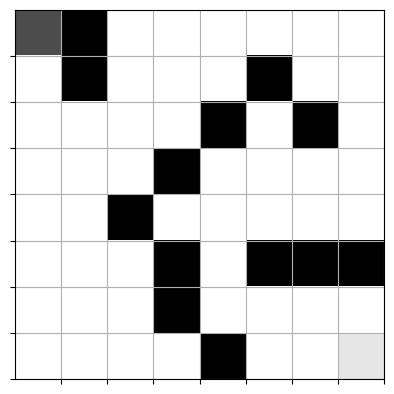

In [ ]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



In [24]:

# CS 499 - Restore DQN training dependencies

import numpy as np
import random
import datetime
import tensorflow as tf

from tensorflow.keras.models import Sequential, clone_model
from tensorflow.keras.layers import Dense, PReLU
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience

# Pirate movement directions
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3

actions_dict = {
    LEFT: "left",
    UP: "up",
    RIGHT: "right",
    DOWN: "down"
}

num_actions = len(actions_dict)

# Original exploration settings
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Original CS 370 maze
maze = np.array([
    [1., 0., 1., 1., 1., 1., 1., 1.],
    [1., 0., 1., 1., 1., 0., 1., 1.],
    [1., 1., 1., 1., 0., 1., 0., 1.],
    [1., 1., 1., 0., 1., 1., 1., 1.],
    [1., 1., 0., 1., 1., 1., 1., 1.],
    [1., 1., 1., 0., 1., 0., 0., 0.],
    [1., 1., 1., 0., 1., 1., 1., 1.],
    [1., 1., 1., 1., 0., 1., 1., 1.]
])

# Original TensorFlow training helper
loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)

    grads = tape.gradient(
        loss, model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(grads, model.trainable_variables)
    )

    return loss

print("DQN dependencies loaded successfully!")
print("Maze shape:", maze.shape)
print("Number of actions:", num_actions)


DQN dependencies loaded successfully!
Maze shape: (8, 8)
Number of actions: 4


In [25]:
# CS 499: Retrain and save the DQN model

# Restore the TreasureMaze class reference.
from TreasureMaze import TreasureMaze

# Build and train the neural network.

model = build_model(maze)
qtrain(model, maze, n_epoch=1000, max_memory=8*maze.size, data_size=32, target_update_freq=50)

# Verify whether the trained model solves the maze.
passed = completion_check(model, maze)
print("DQN completion check:", passed)

# Save the model so its learned weights can be reused.
model.save("pirate_dqn.keras")
print("DQN model saved as pirate_dqn.keras")


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch: 000/999 | Loss: 0.5704 | Episodes: 149 | Win count: 0 | Win rate: 0.000 | time: 1.7 seconds
Epoch: 001/999 | Loss: 0.3435 | Episodes: 148 | Win count: 0 | Win rate: 0.000 | time: 2.5 seconds
Epoch: 002/999 | Loss: 0.0533 | Episodes: 27 | Win count: 1 | Win rate: 0.000 | time: 2.6 seconds
Epoch: 003/999 | Loss: 0.3812 | Episodes: 153 | Win count: 1 | Win rate: 0.000 | time: 3.4 seconds
Epoch: 004/999 | Loss: 0.4058 | Episodes: 149 | Win count: 1 | Win rate: 0.000 | time: 4.2 seconds
Epoch: 005/999 | Loss: 0.0018 | Episodes: 1 | Win count: 2 | Win rate: 0.000 | time: 4.2 seconds
Epoch: 006/999 | Loss: 0.0246 | Episodes: 8 | Win count: 3 | Win rate: 0.000 | time: 4.3 seconds
Epoch: 007/999 | Loss: 0.6279 | Episodes: 151 | Win count: 3 | Win rate: 0.000 | time: 5.1 seconds
Epoch: 008/999 | Loss: 0.0094 | Episodes: 3 | Win count: 4 | Win rate: 0.000 | time: 5.1 seconds
Epoch: 009/999 | Loss: 0.5886 | Episodes: 147 | Win count: 4 | Win rate: 0.000 | time: 6.0 seconds
Epoch: 010/999 | 

In [10]:
print("build_model available:", callable(build_model))

build_model available: True


<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

In [ ]:
completion_check(model, qmaze)


True

This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

In [ ]:
pirate_start = (0, 0)
play_game(model, qmaze, pirate_start)


True

In [32]:
import importlib
import TreasureMaze

importlib.reload(TreasureMaze)

test_maze = TreasureMaze.TreasureMaze(maze)
_, reward, status = test_maze.act(0)  # Move left from (0, 0)

print("Reward:", reward)
print("State:", test_maze.state)
print("Status:", status)

assert reward == -0.75
assert test_maze.state == (0, 0, 'invalid')
print("Invalid movement test PASSED!")

Reward: -0.75
State: (0, 0, 'invalid')
Status: not_over
Invalid movement test PASSED!



## CS 499 Enhancement Two: Algorithms and Data Structures

For this enhancement, I expanded my original Pirate Intelligent
Agent project by implementing the A* pathfinding algorithm.

The original project used Deep Q-Learning to train the pirate
to navigate a maze and locate treasure. My enhancement uses
a priority queue, dictionaries, sets, and the Manhattan
distance heuristic to calculate shortest paths.

I also added path visualization, performance measurements,
and automated tests to evaluate the algorithm.


In [ ]:

import importlib
import TreasureMaze

importlib.reload(TreasureMaze)

qmaze = TreasureMaze.TreasureMaze(maze)

print("Neighbors of (0, 0):", qmaze.get_neighbors((0, 0)))
print("Neighbors of (3, 3):", qmaze.get_neighbors((3, 3)))



Neighbors of (0, 0): [(1, 0)]
Neighbors of (3, 3): []


In [30]:

# CS 499 Enhancement Two: A* Pathfinding
# This algorithm finds the shortest path to the treasure
# using a priority queue and Manhattan distance.

import heapq

def manhattan_distance(cell, goal):
    # Estimate the distance between two cells.
    return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])


def astar_search(qmaze, start, goal=None):
    if goal is None:
        goal = qmaze.target

    # Verify that the starting position is accessible.
    if qmaze._maze[start] != 1.0:
        return []

    # Priority queue: (estimated total cost, current cell)
    open_list = []
    heapq.heappush(open_list, (manhattan_distance(start, goal), start))

    # Track the shortest known distance and previous cell.
    came_from = {}
    g_score = {start: 0}
    closed_set = set()

    while open_list:
        _, current = heapq.heappop(open_list)

        if current in closed_set:
            continue

        # Reconstruct the path when the treasure is reached.
        if current == goal:
            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            return path[::-1]

        closed_set.add(current)

        # Examine each accessible neighboring cell.
        for neighbor in qmaze.get_neighbors(current):
            if neighbor in closed_set:
                continue

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float('inf')):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + manhattan_distance(
                    neighbor, goal
                )

                heapq.heappush(open_list, (f_score, neighbor))

    # Return an empty path if the treasure cannot be reached.
    return []


In [ ]:

# CS 499 Enhancement Two: Test A* pathfinding

qmaze = TreasureMaze.TreasureMaze(maze)

start = (0, 0)
path = astar_search(qmaze, start)

print("Starting position:", start)
print("Treasure location:", qmaze.target)
print("Path found:", bool(path))
print("Number of moves:", len(path) - 1 if path else 0)
print("Path:", path)


Starting position: (0, 0)
Treasure location: (7, 7)
Path found: True
Number of moves: 24
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (1, 3), (1, 4), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4), (5, 4), (6, 4), (6, 5), (6, 6), (6, 7), (7, 7)]


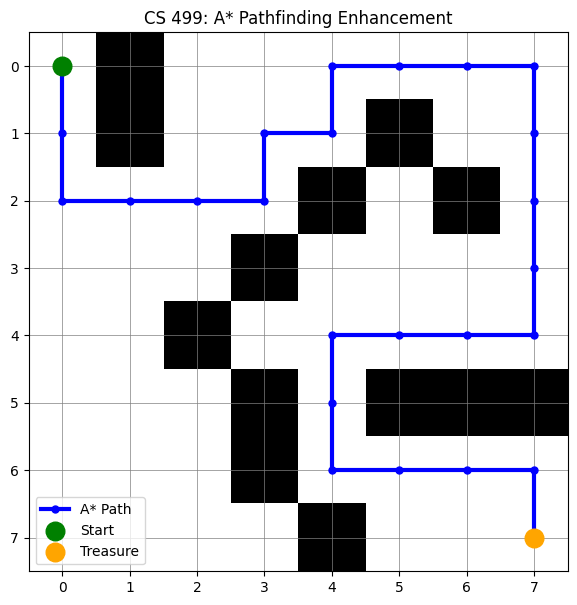

In [ ]:

# CS 499 Enhancement Two: Visualize the A* path

import matplotlib.pyplot as plt
import numpy as np

def visualize_astar(qmaze, path):
    fig, ax = plt.subplots(figsize=(7, 7))

    # Display the original maze.
    ax.imshow(qmaze._maze, cmap='gray', vmin=0, vmax=1)

    if path:
        rows = [cell[0] for cell in path]
        cols = [cell[1] for cell in path]

        # Draw the route found by A*.
        ax.plot(cols, rows, color='blue',
                linewidth=3, marker='o',
                markersize=5, label='A* Path')

        # Highlight the starting position.
        ax.scatter(cols[0], rows[0], color='green',
                   s=180, zorder=5, label='Start')

        # Highlight the treasure.
        ax.scatter(cols[-1], rows[-1], color='orange',
                   s=180, zorder=5, label='Treasure')

    ax.set_xticks(range(qmaze._maze.shape[1]))
    ax.set_yticks(range(qmaze._maze.shape[0]))
    ax.grid(color='gray', linewidth=0.5)
    ax.set_title('CS 499: A* Pathfinding Enhancement')
    ax.legend()
    plt.show()


visualize_astar(qmaze, path)


In [ ]:

# CS 499 Enhancement Two: Test A* from all starting positions

successful_paths = 0
path_lengths = []

for start_cell in qmaze.free_cells:
    test_path = astar_search(qmaze, start_cell)

    if test_path and test_path[-1] == qmaze.target:
        successful_paths += 1
        path_lengths.append(len(test_path) - 1)

total_starts = len(qmaze.free_cells)
success_rate = (successful_paths / total_starts) * 100

print("Total starting positions:", total_starts)
print("Successful paths:", successful_paths)
print(f"Success rate: {success_rate:.1f}%")

if path_lengths:
    print(f"Average path length: {np.mean(path_lengths):.2f} moves")
    print("Shortest path:", min(path_lengths), "moves")
    print("Longest path:", max(path_lengths), "moves")


Total starting positions: 50
Successful paths: 50
Success rate: 100.0%
Average path length: 15.64 moves
Shortest path: 1 moves
Longest path: 28 moves


In [ ]:

# CS 499 Enhancement Two: Measure A* search performance

import time

start_time = time.perf_counter()

for start_cell in qmaze.free_cells:
    astar_search(qmaze, start_cell)

elapsed_time = time.perf_counter() - start_time

print(f"Total A* search time: {elapsed_time:.6f} seconds")
print(f"Average search time: {elapsed_time / len(qmaze.free_cells):.6f} seconds")


Total A* search time: 0.008175 seconds
Average search time: 0.000164 seconds


In [ ]:

# CS 499 Enhancement Two: Automated A* Tests

# Test 1: A* finds the expected shortest path.
test_path = astar_search(qmaze, (0, 0))
assert len(test_path) - 1 == 24
print("Test 1 PASSED: Shortest path is 24 moves.")

# Test 2: A* rejects a blocked starting position.
blocked_path = astar_search(qmaze, (3, 3))
assert blocked_path == []
print("Test 2 PASSED: Blocked starting cell rejected.")

# Test 3: A* reaches the treasure from every free cell.
for start_cell in qmaze.free_cells:
    result = astar_search(qmaze, start_cell)
    assert result
    assert result[0] == start_cell
    assert result[-1] == qmaze.target

print("Test 3 PASSED: All 50 starting positions reach treasure.")

# Test 4: Every step in the path must be legal.
for start_cell in qmaze.free_cells:
    result = astar_search(qmaze, start_cell)

    for current, next_cell in zip(result, result[1:]):
        assert next_cell in qmaze.get_neighbors(current)

print("Test 4 PASSED: Every movement is valid.")

# Test 5: A* handles an unreachable treasure.
unreachable_maze = np.array([
    [1., 0., 0.],
    [0., 0., 0.],
    [0., 0., 1.]
])

unreachable_qmaze = TreasureMaze.TreasureMaze(
    unreachable_maze
)

unreachable_path = astar_search(
    unreachable_qmaze, (0, 0)
)

assert unreachable_path == []
print("Test 5 PASSED: Unreachable treasure handled.")

print("\nAll 5 automated tests passed!")


Test 1 PASSED: Shortest path is 24 moves.
Test 2 PASSED: Blocked starting cell rejected.
Test 3 PASSED: All 50 starting positions reach treasure.
Test 4 PASSED: Every movement is valid.
Test 5 PASSED: Unreachable treasure handled.

All 5 automated tests passed!


In [1]:

# CS 499 Enhancement Two:
# Check whether the DQN model is available for comparison.

if 'model' in globals():
    print("DQN model exists in memory.")
    print("Model type:", type(model).__name__)
else:
    print("DQN model is not currently loaded.")


DQN model is not currently loaded.


In [2]:

# Check whether the DQN dependencies are installed.

import sys
import importlib.util

print("Python:", sys.executable)

if importlib.util.find_spec("tensorflow"):
    print("TensorFlow is installed.")
else:
    print("TensorFlow is NOT installed.")

if importlib.util.find_spec("keras"):
    print("Keras is installed.")
else:
    print("Keras is NOT installed.")


Python: /usr/local/bin/python3
TensorFlow is NOT installed.
Keras is NOT installed.


In [3]:

%pip install "numpy==1.26.4" "tensorflow==2.16.2"


  Using cached numpy-1.26.4-cp310-cp310-macosx_11_0_arm64.whl (14.0 MB)
     |████████████████████████████████| 227.0 MB 9.8 MB/s eta 0:00:011    |█████▍                          | 37.9 MB 22.7 MB/s eta 0:00:09     |█████████████▍                  | 95.3 MB 10.4 MB/s eta 0:00:13
     |████████████████████████████████| 25.8 MB 8.1 MB/s eta 0:00:011
     |████████████████████████████████| 3.5 MB 14.7 MB/s eta 0:00:01
     |████████████████████████████████| 73 kB 3.9 MB/s eta 0:00:01
     |████████████████████████████████| 5.5 MB 7.8 MB/s eta 0:00:01
     |████████████████████████████████| 57 kB 10.4 MB/s eta 0:00:01
  Using cached absl_py-2.5.1-py3-none-any.whl (137 kB)
  Using cached keras-3.12.4-py3-none-any.whl (2.1 MB)
     |████████████████████████████████| 12.7 MB 5.1 MB/s eta 0:00:011MB 14.5 MB/s eta 0:00:01
     |████████████████████████████████| 389 kB 9.2 MB/s eta 0:00:01
     |████████████████████████████████| 105 kB 19.4 MB/s eta 0:00:01
  Using cached h5py-3.16.0-cp310-cp310

In [5]:


# CS 499: Verify DQN dependencies

import numpy as np
import tensorflow as tf
import keras

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

# Test a basic TensorFlow operation.
test = tf.constant([1.0, 2.0, 3.0])
print("TensorFlow test:", test.numpy())

print("All dependencies are working!")


NumPy: 1.26.4
TensorFlow: 2.16.2
Keras: 3.12.4
TensorFlow test: [1. 2. 3.]
All dependencies are working!


In [27]:

# Check for missing dependencies before DQN training.

import inspect

functions = [
    build_model,
    qtrain,
    play_game,
    completion_check
]

for function in functions:
    missing = inspect.getclosurevars(function).unbound

    if missing:
        print(function.__name__, "MISSING:", sorted(missing))
    else:
        print(function.__name__, "READY")

print("Maze shape:", maze.shape)


build_model MISSING: ['add', 'size']
qtrain MISSING: ['act', 'append', 'argmax', 'choice', 'free_cells', 'get', 'get_data', 'get_weights', 'now', 'observe', 'predict', 'rand', 'remember', 'reset', 'set_weights', 'size', 'total_seconds', 'valid_actions']
play_game MISSING: ['act', 'argmax', 'asarray', 'expand_dims', 'float32', 'ndim', 'numpy', 'observe', 'reset', 'size']
completion_check MISSING: ['free_cells', 'valid_actions']
Maze shape: (8, 8)


In [31]:

# CS 499: DQN vs. A* pathfinding comparison

import numpy as np
from TreasureMaze import TreasureMaze

goal = (maze.shape[0] - 1, maze.shape[1] - 1)
qmaze = TreasureMaze(maze)

# Compare the same valid starting positions.
start_cells = [
    tuple(cell) for cell in qmaze.free_cells
    if tuple(cell) != goal
]

def measure_dqn_moves(start):
    game = TreasureMaze(maze)
    game.reset(start)
    state = game.observe()

    max_steps = maze.size * 4

    for moves in range(1, max_steps + 1):
        observation = np.asarray(
            state, dtype=np.float32
        ).reshape(1, -1)

        q_values = model(
            observation, training=False
        ).numpy()

        action = int(np.argmax(q_values[0]))
        state, reward, status = game.act(action)

        if status == "win":
            return moves

        if status == "lose":
            return None

    return None

results = []

for start in start_cells:
    dqn_moves = measure_dqn_moves(start)

    path = astar_search(qmaze, start)
    astar_moves = len(path) - 1 if path else None

    results.append((start, dqn_moves, astar_moves))

dqn_successes = [
    r[1] for r in results if r[1] is not None
]
astar_successes = [
    r[2] for r in results if r[2] is not None
]

print("DQN vs. A* Comparison")
print("----------------------")
print("Starting positions:", len(results))
print("DQN successes:", len(dqn_successes))
print("A* successes:", len(astar_successes))

if dqn_successes:
    print(
        "DQN average moves:",
        round(np.mean(dqn_successes), 2)
    )

if astar_successes:
    print(
        "A* average moves:",
        round(np.mean(astar_successes), 2)
    )

print("\nRoute from (0, 0):")

for start, dqn_moves, astar_moves in results:
    if start == (0, 0):
        print("DQN moves:", dqn_moves)
        print("A* moves:", astar_moves)
        break


DQN vs. A* Comparison
----------------------
Starting positions: 50
DQN successes: 50
A* successes: 50
DQN average moves: 15.96
A* average moves: 15.64

Route from (0, 0):
DQN moves: 24
A* moves: 24


In [32]:

# CS 499: Verify saved DQN model

from tensorflow.keras.models import load_model

saved_model = load_model(
    "pirate_dqn.keras",
    compile=False
)

print("Saved model loaded successfully!")

passed = completion_check(saved_model, maze)

print("Saved DQN completion check:", passed)


Saved model loaded successfully!
Saved DQN completion check: True


## Save and Submit Your Work

<div class="alert alert-block alert-info" style="color:black;">
    <b>Hint:</b> To use the markdown block below, double click in the <b>Type Markdown and LaTeX:  𝛼2</b> block below, to turn it back to html, Run the cell.
</div>

After you have finished creating the code for your notebook, save your work.
Make sure that your notebook contains your name in the filename (e.g. Doe_Jane_ProjectTwo.html). Download this file as an .html file clicking on ***file*** in *Jupyter Notebook*, navigating down to ***Download as*** and clicking on ***.html***. 
Download a copy of your .html file and submit it to Brightspace.

When I originally developed my Pirate Intelligent Agent in CS 370, I used Deep Q-Learning (DQN) to train the pirate to find treasure in a maze. One challenge was getting the agent to consistently succeed from different starting positions. Even after reaching a 100% training win rate, the completion check initially failed. After reviewing how the code handled movement and game status, I made improvements that allowed the agent to pass the completion check at epoch 635.
For my CS 499 enhancement, I implemented the A* pathfinding algorithm to explore another way of solving the maze. Unlike DQN, which learns through training, A* uses the maze layout and a heuristic to calculate the shortest path. I enjoyed visualizing the route and seeing how the algorithm avoided obstacles. A* successfully reached the treasure from all 50 starting positions, with an average path length of 15.64 moves. All five automated tests also passed. This enhancement helped me understand how different algorithms can solve the same problem and why choosing the right approach depends on the situation. It also reinforced the importance of troubleshooting, testing, and evaluating results rather than assuming a program works simply because it produces a successful outcome.

The pirate successfully passed at epoch 635, taking approximately 11.71 minutes, and both final tests returned True